# Analisis Perbandingan HDBSCAN: Euclidean, Manhattan, Cosine

## 0. Setup

In [1]:
import json
import base64
import io
import ast
from pathlib import Path
from html.parser import HTMLParser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

plt.rcParams['figure.dpi'] = 120
OUTPUT_DIR = Path('outputPerbandinganHDBSCAN')
OUTPUT_DIR.mkdir(exist_ok=True)
METRIC_ORDER = ['Euclidean', 'Manhattan', 'Cosine']

## 1. Menentukan Ketiga File Notebook

In [2]:
BASE_DIR = Path.cwd()
FILES = {
    'Euclidean': BASE_DIR / 'HDBSCAN_Euclidian.ipynb',
    'Manhattan': BASE_DIR / 'HDBSCAN_Manhattan.ipynb',
    'Cosine': BASE_DIR / 'HDBSCAN_Cosine.ipynb',
}
for metric, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f'{path}: sesuaikan BASE_DIR atau nama file pada bagian 1.')
    print(f'{metric}: {path.name}')

Euclidean: HDBSCAN_Euclidian.ipynb
Manhattan: HDBSCAN_Manhattan.ipynb
Cosine: HDBSCAN_Cosine.ipynb


## 2. Fungsi Membaca Output Notebook

In [3]:
def as_text(value):
    return ''.join(value) if isinstance(value, list) else str(value)

class TableReader(HTMLParser):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.row = None
        self.cell = None
    def handle_starttag(self, tag, attrs):
        if tag == 'tr':
            self.row = []
        elif tag in ('th', 'td') and self.row is not None:
            self.cell = []
    def handle_data(self, data):
        if self.cell is not None:
            self.cell.append(data)
    def handle_endtag(self, tag):
        if tag in ('th', 'td') and self.cell is not None:
            self.row.append(''.join(self.cell).strip())
            self.cell = None
        elif tag == 'tr' and self.row is not None:
            self.rows.append(self.row)
            self.row = None

def load_notebook(path):
    with path.open(encoding='utf-8') as handle:
        return json.load(handle)

In [4]:
REQUIRED = ['Metode', 'Metrik_Jarak', 'Metrik_Silhouette', 'Min_Cluster_Size',
            'Min_Samples', 'Jumlah_Data', 'Jumlah_Cluster', 'Jumlah_Noise',
            'Persentase_Noise', 'Jumlah_Data_Evaluasi', 'Evaluasi_Valid',
            'Waktu_Detik', 'Peak_Memory_MB', 'Silhouette', 'DBI', 'Calinski_Harabasz']
SCORES = ['Silhouette', 'DBI', 'Calinski_Harabasz']
COUNTS = ['Min_Cluster_Size', 'Min_Samples', 'Jumlah_Data', 'Jumlah_Cluster',
          'Jumlah_Noise', 'Jumlah_Data_Evaluasi']
NUMERIC = COUNTS + ['Persentase_Noise', 'Waktu_Detik', 'Peak_Memory_MB'] + SCORES

def extract_metrics(nb, path, expected_metric):
    for cell in nb['cells']:
        if 'df_eval =' not in as_text(cell.get('source', [])):
            continue
        for output in reversed(cell.get('outputs', [])):
            html = output.get('data', {}).get('text/html')
            if not html:
                continue
            reader = TableReader()
            reader.feed(as_text(html))
            if not reader.rows or not set(REQUIRED).issubset(reader.rows[0]):
                continue
            headers = reader.rows[0]
            records = [dict(zip(headers, row)) for row in reader.rows[1:]
                       if len(row) == len(headers)]
            frame = pd.DataFrame(records)[REQUIRED].copy()
            if len(frame) != 1 or frame['Metode'].iloc[0] != 'HDBSCAN':
                raise ValueError(f'{path.name}: tabel harus berisi satu hasil HDBSCAN.')
            if frame['Metrik_Jarak'].iloc[0] != expected_metric:
                raise ValueError(f'{path.name}: metrik tabel tidak sesuai {expected_metric}.')
            valid_text = str(frame['Evaluasi_Valid'].iloc[0]).lower()
            if valid_text not in ('true', 'false'):
                raise ValueError(f'{path.name}: Evaluasi_Valid tidak dikenali.')
            valid = valid_text == 'true'
            frame['Evaluasi_Valid'] = valid
            for column in NUMERIC:
                frame[column] = pd.to_numeric(frame[column].replace({'NaN': np.nan, 'nan': np.nan}), errors='raise')
            basic = [x for x in NUMERIC if x not in SCORES]
            if not np.isfinite(frame[basic].to_numpy(dtype=float)).all():
                raise ValueError(f'{path.name}: jumlah/waktu/memori tidak valid.')
            if valid and not np.isfinite(frame[SCORES].to_numpy(dtype=float)).all():
                raise ValueError(f'{path.name}: evaluasi valid tetapi skor tidak tersedia.')
            if not valid and not frame[SCORES].isna().all().all():
                raise ValueError(f'{path.name}: evaluasi tidak valid tetapi skor masih terisi.')
            for column in COUNTS:
                value = frame[column].iloc[0]
                if value < 0 or value != int(value):
                    raise ValueError(f'{path.name}: {column} bukan hitungan valid.')
                frame[column] = frame[column].astype(int)
            row = frame.iloc[0]
            if row['Jumlah_Data_Evaluasi'] + row['Jumlah_Noise'] != row['Jumlah_Data']:
                raise ValueError(f'{path.name}: jumlah data/noise/evaluasi tidak konsisten.')
            expected_noise = 100 * row['Jumlah_Noise'] / row['Jumlah_Data']
            if not np.isclose(row['Persentase_Noise'], expected_noise, atol=0.011):
                raise ValueError(f'{path.name}: persentase noise tidak konsisten.')
            frame['File_Sumber'] = path.name
            return frame
    raise ValueError(f'{path.name}: tabel df_eval belum tersimpan. Run All dan Save notebook model.')

def extract_pca(nb, path):
    for cell in nb['cells']:
        source = as_text(cell.get('source', []))
        if 'sns.scatterplot' not in source or 'pca_df' not in source:
            continue
        for output in reversed(cell.get('outputs', [])):
            encoded = output.get('data', {}).get('image/png')
            if encoded:
                with Image.open(io.BytesIO(base64.b64decode(as_text(encoded)))) as image:
                    return image.convert('RGB').copy()
    raise ValueError(f'{path.name}: output PCA belum tersimpan. Jalankan visualisasi dan Save.')

def extract_algorithm(nb):
    for cell in nb['cells']:
        source = as_text(cell.get('source', []))
        if 'clusterer = hdbscan.HDBSCAN(' in source:
            tree = ast.parse(source)
            assignment = next(node for node in tree.body if isinstance(node, ast.Assign)
                              and any(isinstance(t, ast.Name) and t.id == 'clusterer' for t in node.targets))
            options = {item.arg: ast.literal_eval(item.value) for item in assignment.value.keywords}
            return options.get('algorithm', 'best (default)')
    return 'Tidak tercatat'

def preprocessing_signature(nb):
    parts = []
    active = False
    for cell in nb['cells']:
        if cell['cell_type'] != 'code':
            continue
        source = as_text(cell.get('source', []))
        if 'df = pd.read_csv' in source:
            active = True
        if 'clusterer = hdbscan.HDBSCAN(' in source:
            break
        if active:
            parts.append(source)
    return ast.dump(ast.parse('\n'.join(parts)), include_attributes=False)

## 3. Mengambil Hasil Ketiga Metrik

In [5]:
notebooks = {metric: load_notebook(path) for metric, path in FILES.items()}
comparison = pd.concat([
    extract_metrics(notebooks[metric], path, metric)
    for metric, path in FILES.items()
], ignore_index=True)
comparison['Algoritma_Komputasi'] = [extract_algorithm(notebooks[m]) for m in comparison['Metrik_Jarak']]
display(comparison)

,Metode,Metrik_Jarak,Metrik_Silhouette,Min_Cluster_Size,Min_Samples,Jumlah_Data,Jumlah_Cluster,Jumlah_Noise,Persentase_Noise,Jumlah_Data_Evaluasi,Evaluasi_Valid,Waktu_Detik,Peak_Memory_MB,Silhouette,DBI,Calinski_Harabasz,File_Sumber,Algoritma_Komputasi
0,HDBSCAN,Euclidean,Euclidean,15,5,5000,2,2031,40.62,2969,True,2.7865,4.11,0.2163,1.4877,377.2729,HDBSCAN_Euclidian.ipynb,best (default)
1,HDBSCAN,Manhattan,Euclidean,15,5,5000,2,2186,43.72,2814,True,1.9894,4.06,0.2302,1.4343,424.9692,HDBSCAN_Manhattan.ipynb,best (default)
2,HDBSCAN,Cosine,Euclidean,15,5,5000,2,2665,53.30,2335,True,2.7202,476.99,0.3292,1.2777,1340.8484,HDBSCAN_Cosine.ipynb,generic


### 3.1 Pemeriksaan Keselarasan Eksperimen

In [6]:
signatures = [preprocessing_signature(notebooks[m]) for m in METRIC_ORDER]
print('Kode data understanding dan preprocessing sama:', len(set(signatures)) == 1)
if len(set(signatures)) != 1:
    print('Periksa sampling/fitur/preprocessing sebelum menafsirkan perbandingan.')
display(comparison[['Metrik_Jarak', 'Min_Cluster_Size', 'Min_Samples', 'Jumlah_Data',
                    'Jumlah_Cluster', 'Metrik_Silhouette', 'Algoritma_Komputasi']])
print('Skor dihitung pada data non-noise; sampel evaluasi dapat berbeda antar metrik.')
print('Waktu dan memori adalah pengukuran fit_predict, bukan keseluruhan notebook.')
print('Pilihan algoritma komputasi berbeda dapat memengaruhi waktu dan memori.')

Kode data understanding dan preprocessing sama: True


,Metrik_Jarak,Min_Cluster_Size,Min_Samples,Jumlah_Data,Jumlah_Cluster,Metrik_Silhouette,Algoritma_Komputasi
0,Euclidean,15,5,5000,2,Euclidean,best (default)
1,Manhattan,15,5,5000,2,Euclidean,best (default)
2,Cosine,15,5,5000,2,Euclidean,generic


Skor dihitung pada data non-noise; sampel evaluasi dapat berbeda antar metrik.
Waktu dan memori adalah pengukuran fit_predict, bukan keseluruhan notebook.
Pilihan algoritma komputasi berbeda dapat memengaruhi waktu dan memori.


## 4. Diagram Perbandingan Kuantitatif

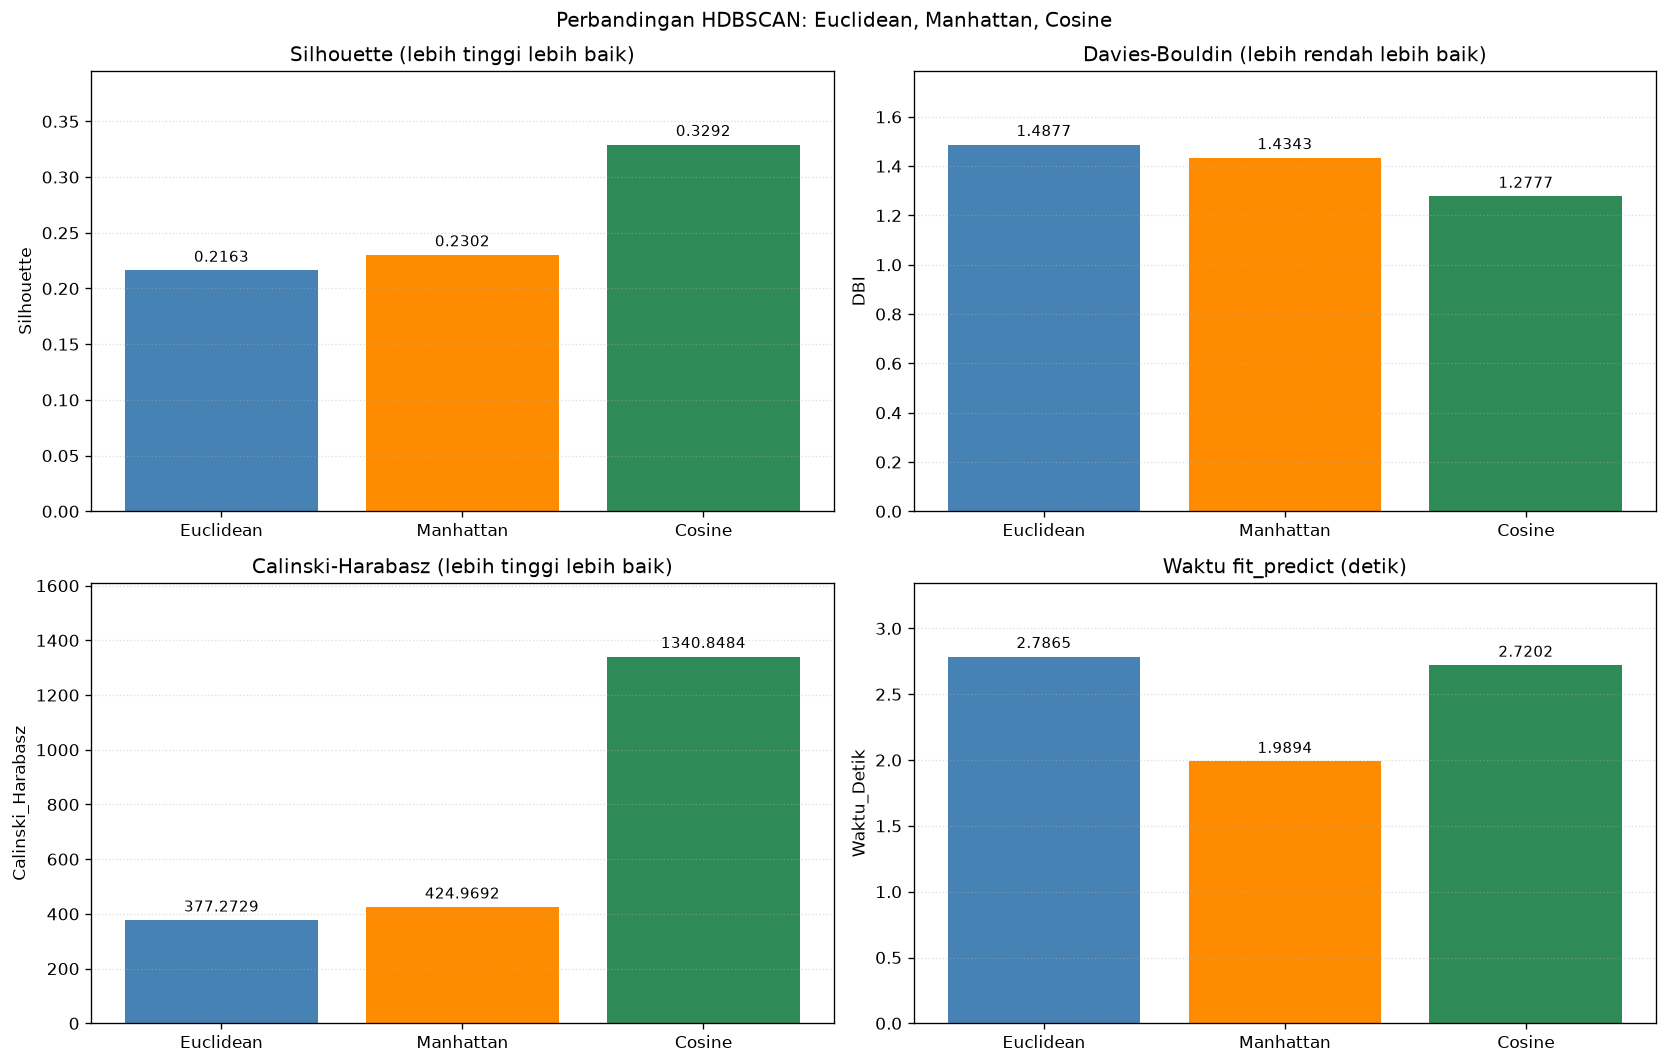

In [7]:
def comparison_bar(ax, column, title):
    values = comparison.set_index('Metrik_Jarak').reindex(METRIC_ORDER)[column].astype(float)
    positions = np.arange(len(values))
    finite = np.isfinite(values.to_numpy())
    bars = ax.bar(positions[finite], values.to_numpy()[finite], color=np.array(['steelblue', 'darkorange', 'seagreen'])[finite])
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    for position in positions[~finite]:
        ax.text(position, 0.03, 'Tidak tersedia', ha='center', transform=ax.get_xaxis_transform(), fontsize=8)
    ax.set_xticks(positions, METRIC_ORDER)
    ax.set_title(title)
    ax.set_ylabel(column)
    ax.grid(axis='y', linestyle=':', alpha=0.4)
    ax.margins(y=0.2)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column, title in zip(axes.flat,
    ['Silhouette', 'DBI', 'Calinski_Harabasz', 'Waktu_Detik'],
    ['Silhouette (lebih tinggi lebih baik)', 'Davies-Bouldin (lebih rendah lebih baik)',
     'Calinski-Harabasz (lebih tinggi lebih baik)', 'Waktu fit_predict (detik)']):
    comparison_bar(ax, column, title)
fig.suptitle('Perbandingan HDBSCAN: Euclidean, Manhattan, Cosine')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_metrik_hdbscan.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. Mengambil Gambar PCA Asli

In [8]:
pca_images = {metric: extract_pca(notebooks[metric], FILES[metric]) for metric in METRIC_ORDER}
print('Ketiga gambar PCA asli berhasil dibaca tanpa menghitung ulang PCA/model.')

Ketiga gambar PCA asli berhasil dibaca tanpa menghitung ulang PCA/model.


## 6. Visualisasi Perbandingan PCA

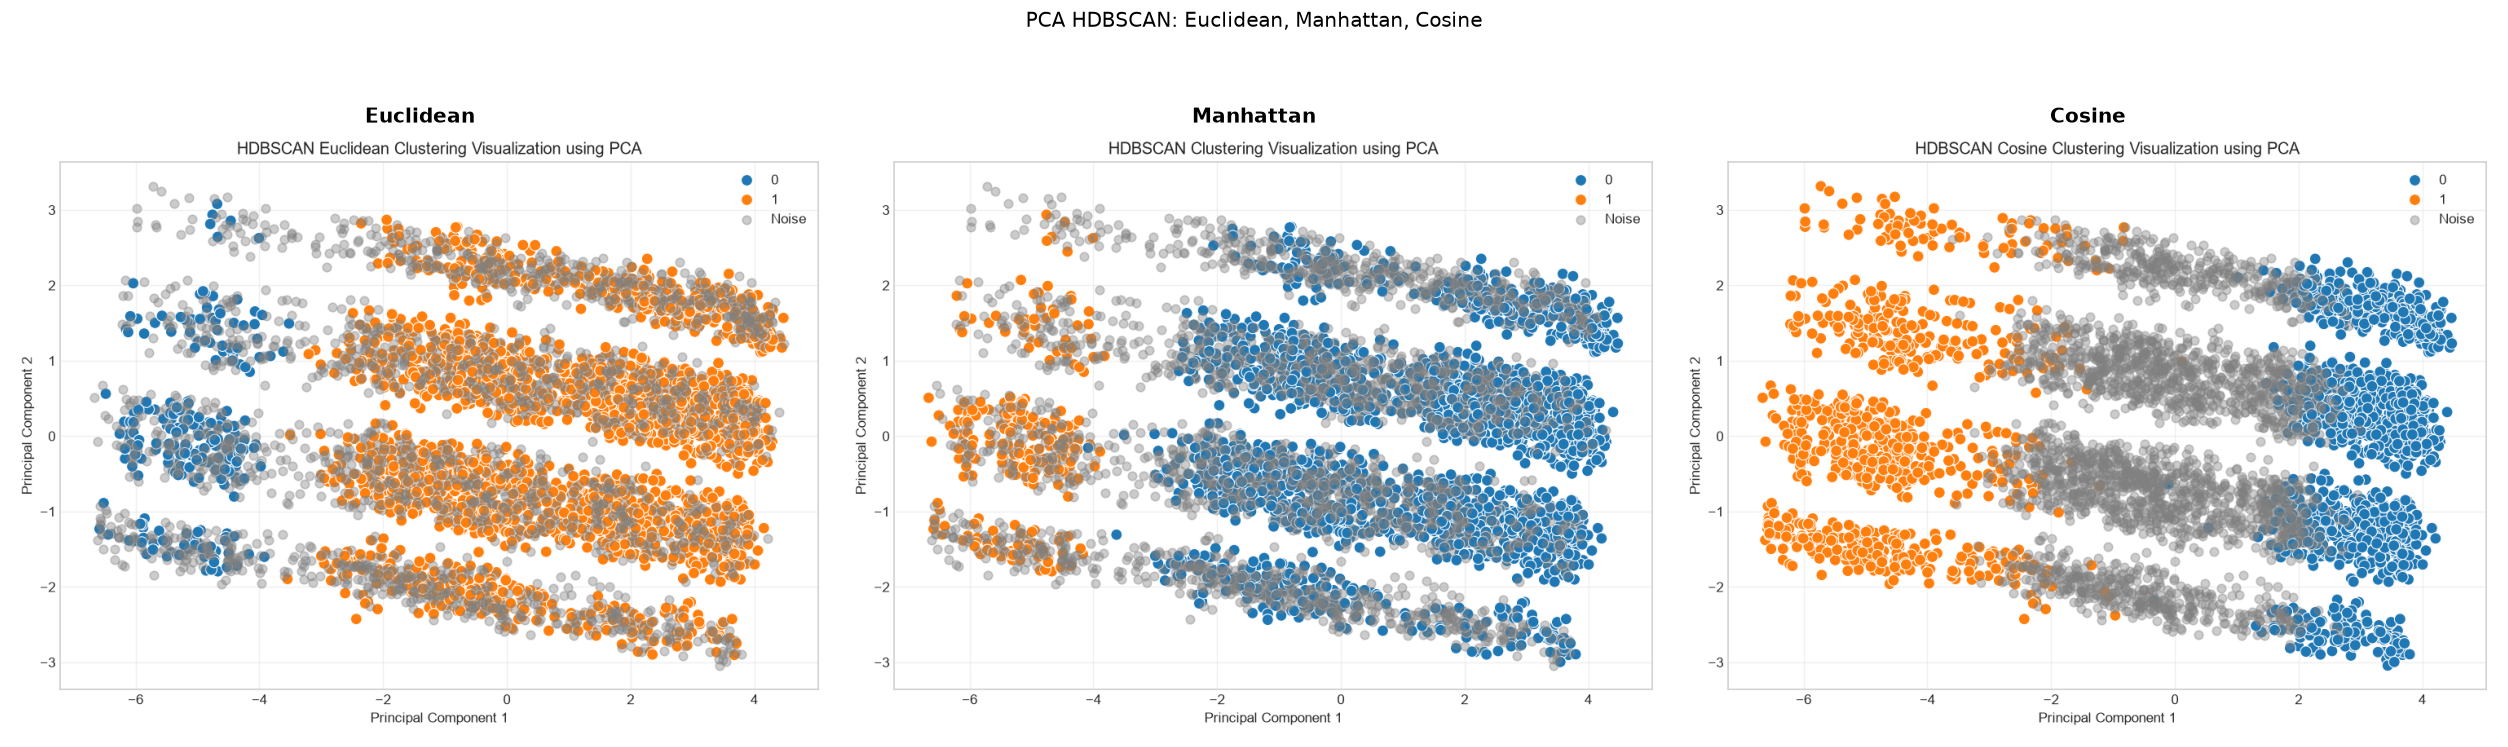

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, metric in zip(axes, METRIC_ORDER):
    ax.imshow(pca_images[metric])
    ax.set_title(metric, fontweight='bold')
    ax.axis('off')
fig.suptitle('PCA HDBSCAN: Euclidean, Manhattan, Cosine')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_pca_hdbscan.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Perbandingan Memori, Klaster, dan Noise

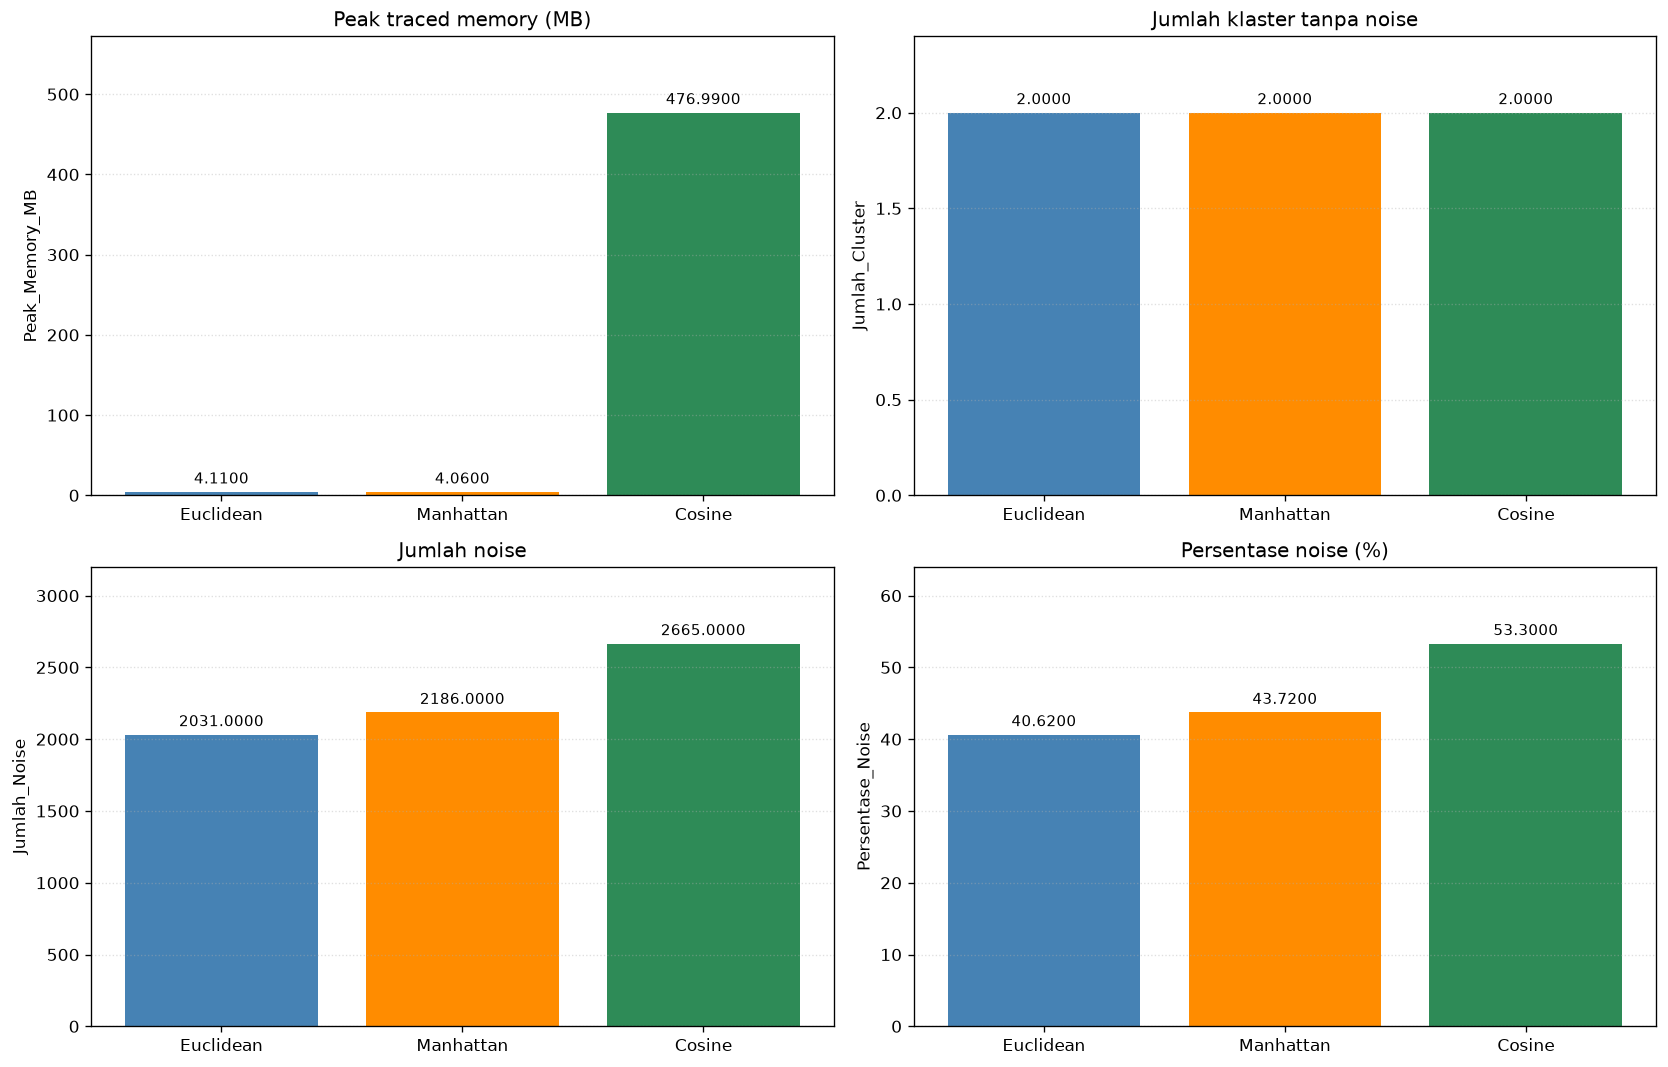

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column, title in zip(axes.flat,
    ['Peak_Memory_MB', 'Jumlah_Cluster', 'Jumlah_Noise', 'Persentase_Noise'],
    ['Peak traced memory (MB)', 'Jumlah klaster tanpa noise', 'Jumlah noise', 'Persentase noise (%)']):
    comparison_bar(ax, column, title)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_efisiensi_noise_hdbscan.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Tabel Hasil Akhir

In [11]:
display(comparison[['Metrik_Jarak', 'Jumlah_Data', 'Jumlah_Cluster', 'Jumlah_Noise',
                    'Persentase_Noise', 'Jumlah_Data_Evaluasi', 'Metrik_Silhouette',
                    'Silhouette', 'DBI', 'Calinski_Harabasz', 'Waktu_Detik', 'Peak_Memory_MB']])

,Metrik_Jarak,Jumlah_Data,Jumlah_Cluster,Jumlah_Noise,Persentase_Noise,Jumlah_Data_Evaluasi,Metrik_Silhouette,Silhouette,DBI,Calinski_Harabasz,Waktu_Detik,Peak_Memory_MB
0,Euclidean,5000,2,2031,40.62,2969,Euclidean,0.2163,1.4877,377.2729,2.7865,4.11
1,Manhattan,5000,2,2186,43.72,2814,Euclidean,0.2302,1.4343,424.9692,1.9894,4.06
2,Cosine,5000,2,2665,53.30,2335,Euclidean,0.3292,1.2777,1340.8484,2.7202,476.99


### 8.1 Panduan Interpretasi Hasil

In [12]:
print('Baca kualitas klaster bersama persentase noise dan jumlah data evaluasi.')
print('Skor tinggi pada sedikit data non-noise tidak otomatis menunjukkan hasil terbaik untuk seluruh dataset.')
print('DBI dan Calinski-Harabasz berbasis geometri Euclidean; periksa kolom Metrik_Silhouette untuk Silhouette.')
print('PCA adalah proyeksi visual; nomor/warna klaster antar notebook tidak menyatakan identitas kelompok yang sama.')
print('Waktu/memori dipengaruhi implementasi, perangkat, dan kondisi eksekusi.')
print('Nilai tabel mengikuti pembulatan sumber. Tidak ada ranking gabungan atau angka yang ditulis manual.')

Baca kualitas klaster bersama persentase noise dan jumlah data evaluasi.
Skor tinggi pada sedikit data non-noise tidak otomatis menunjukkan hasil terbaik untuk seluruh dataset.
DBI dan Calinski-Harabasz berbasis geometri Euclidean; periksa kolom Metrik_Silhouette untuk Silhouette.
PCA adalah proyeksi visual; nomor/warna klaster antar notebook tidak menyatakan identitas kelompok yang sama.
Waktu/memori dipengaruhi implementasi, perangkat, dan kondisi eksekusi.
Nilai tabel mengikuti pembulatan sumber. Tidak ada ranking gabungan atau angka yang ditulis manual.


## 9. Ekspor Hasil Perbandingan

In [13]:
comparison.to_csv(OUTPUT_DIR / 'perbandingan_hdbscan.csv', index=False)
try:
    comparison.to_excel(OUTPUT_DIR / 'perbandingan_hdbscan.xlsx', index=False)
except ImportError:
    print('CSV tersimpan. Untuk ekspor Excel: %pip install openpyxl pada kernel yang digunakan.')
print(f'Hasil disimpan ke: {OUTPUT_DIR.resolve()}')
for path in sorted(OUTPUT_DIR.glob('*')):
    print('-', path.name)

Hasil disimpan ke: D:\My Files\File Penting\MachineLearning\Pertemuan_7\UTS\outputPerbandinganHDBSCAN
- perbandingan_efisiensi_noise_hdbscan.png
- perbandingan_hdbscan.csv
- perbandingan_hdbscan.xlsx
- perbandingan_metrik_hdbscan.png
- perbandingan_pca_hdbscan.png
